In [ ]:
from pathlib import Path
import numpy as np


ROOT = Path(
    "/home/leonel.cabello/datosmunin3/TP_MACHINE_LEARNING_2026"
)

PROJECT = ROOT / "ParamDiffussion-main"


# Flow Matching 100 NFE


FM_RUN = (
    "FMRESIDFlowMatching_Residual_ResidualSqrTransforms_"
    "s0_33b74bX13ce29"
)

FM_DIR = (
    PROJECT
    / "final_models"
    / FM_RUN
    / "test_sampling"
    / "rk4_0100nfe"
)

FM_SIM_FILE = (
    FM_DIR
    / "simulations_test_top100_100nfe.npy"
)

# DDPM - 1000 NFE

DDPM_RUN = (
    "RESIDResidual_ResidualSqrTransforms_"
    "s0_e22d80X13ce29"
)

DDPM_DIR = (
    PROJECT
    / "final_models"
    / DDPM_RUN
    / "test_sampling"
    / "ddpm_1000nfe"
)

DDPM_SIM_FILE = (
    DDPM_DIR
    / "simulations_test_top100_1000nfe.npy"
)


# Observaciones

OBS_FILE = (
    FM_DIR
    / "observations_test_top100.npy"
)


# Carga de datos

sim_fm = np.load(FM_SIM_FILE)
sim_ddpm = np.load(DDPM_SIM_FILE)
obs = np.load(OBS_FILE)


# Shapes

print("FM 100 NFE :", sim_fm.shape)
print("DDPM 1000 NFE:", sim_ddpm.shape)
print("ERA5 observado:", obs.shape)


assert sim_fm.shape == (100, 80, 64, 64)
assert sim_ddpm.shape == (100, 80, 64, 64)
assert obs.shape == (100, 64, 64)

FM 100 NFE : (100, 80, 64, 64)
DDPM 1000 NFE: (100, 80, 64, 64)
ERA5 observado: (100, 64, 64)


In [ ]:
# Flatten

obs_flat = obs.reshape(-1)

fm_flat = sim_fm.reshape(-1)

ddpm_flat = sim_ddpm.reshape(-1)


print("ERA5:", obs_flat.shape)
print("FM:", fm_flat.shape)
print("DDPM:", ddpm_flat.shape)

print()

print(
    "ERA5 min/max:",
    obs_flat.min(),
    obs_flat.max(),
)

print(
    "FM min/max:",
    fm_flat.min(),
    fm_flat.max(),
)

print(
    "DDPM min/max:",
    ddpm_flat.min(),
    ddpm_flat.max(),
)

ERA5: (409600,)
FM: (32768000,)
DDPM: (32768000,)

ERA5 min/max: 0.0 264.20306
FM min/max: 0.0 323.88632
DDPM min/max: 0.0 419.66373


In [ ]:
# Probabilidades de excedencia

thresholds = [
    1,
    5,
    10,
    20,
    50,
    100,
    150,
    200,
    250,
    300,
    400,
]


for threshold in thresholds:

    p_obs = np.mean(
        obs_flat > threshold
    )

    p_fm = np.mean(
        fm_flat > threshold
    )

    p_ddpm = np.mean(
        ddpm_flat > threshold
    )

    print(
        f"{threshold:>4} mm/día | "
        f"ERA5 = {p_obs:.8f} | "
        f"FM = {p_fm:.8f} | "
        f"DDPM = {p_ddpm:.8f}"
    )

   1 mm/día | ERA5 = 0.61271973 | FM = 0.61884402 | DDPM = 0.61884781
   5 mm/día | ERA5 = 0.42216553 | FM = 0.42649750 | DDPM = 0.42622025
  10 mm/día | ERA5 = 0.31350342 | FM = 0.31782355 | DDPM = 0.31848343
  20 mm/día | ERA5 = 0.19147705 | FM = 0.19390338 | DDPM = 0.19386444
  50 mm/día | ERA5 = 0.05929687 | FM = 0.04761334 | DDPM = 0.04882538
 100 mm/día | ERA5 = 0.00670410 | FM = 0.00259094 | DDPM = 0.00353363
 150 mm/día | ERA5 = 0.00058350 | FM = 0.00012247 | DDPM = 0.00026279
 200 mm/día | ERA5 = 0.00007080 | FM = 0.00000958 | DDPM = 0.00003665
 250 mm/día | ERA5 = 0.00000977 | FM = 0.00000082 | DDPM = 0.00000806
 300 mm/día | ERA5 = 0.00000000 | FM = 0.00000003 | DDPM = 0.00000183
 400 mm/día | ERA5 = 0.00000000 | FM = 0.00000000 | DDPM = 0.00000003


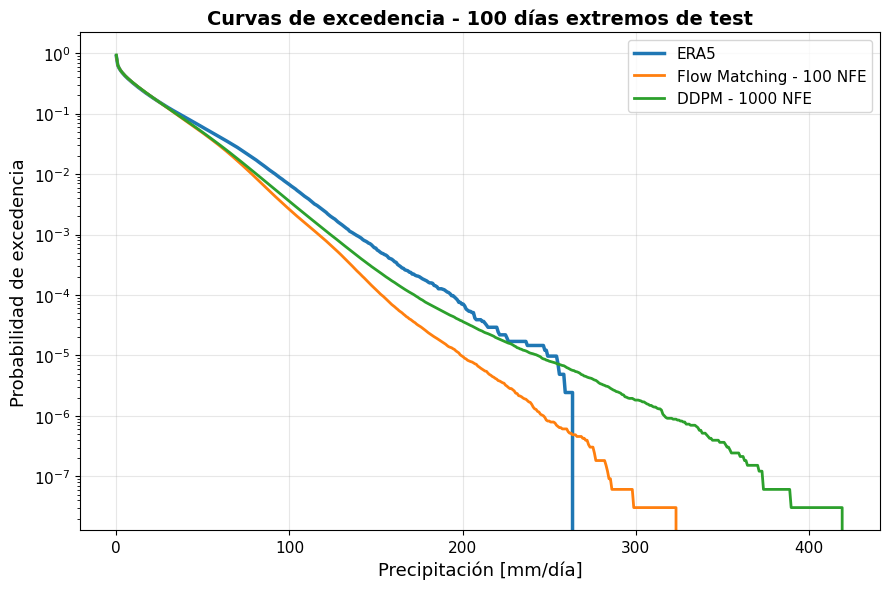

In [ ]:
# Curvas de excedencia

import matplotlib.pyplot as plt


# Umbrales de precipitación
thresholds = np.linspace(
    0.0,
    420.0,
    500,
)


# Probabilidad de excedencia para cada umbral
exc_obs = np.array([
    np.mean(obs_flat > threshold)
    for threshold in thresholds
])

exc_fm = np.array([
    np.mean(fm_flat > threshold)
    for threshold in thresholds
])

exc_ddpm = np.array([
    np.mean(ddpm_flat > threshold)
    for threshold in thresholds
])


# Figura

plt.figure(
    figsize=(9, 6)
)


plt.plot(
    thresholds,
    exc_obs,
    linewidth=2.5,
    label="ERA5",
)

plt.plot(
    thresholds,
    exc_fm,
    linewidth=2.0,
    label="Flow Matching - 100 NFE",
)

plt.plot(
    thresholds,
    exc_ddpm,
    linewidth=2.0,
    label="DDPM - 1000 NFE",
)


plt.yscale(
    "log"
)


plt.xlabel(
    "Precipitación [mm/día]",
    fontsize=13,
)

plt.ylabel(
    "Probabilidad de excedencia",
    fontsize=13,
)


plt.title(
    "Curvas de excedencia - 100 días extremos de test",
    fontsize=14,
    fontweight="bold",
)


plt.grid(
    alpha=0.3
)

plt.legend(
    fontsize=11
)

plt.tick_params(
    labelsize=11
)

plt.tight_layout()

plt.show()

In [ ]:
# Curvas de excedencia por miembro del ensamble

import numpy as np
import matplotlib.pyplot as plt


# Umbrales

thresholds = np.linspace(
    0.0,
    430.0,
    600,
)


# Función que calcula la excedencia

def exceedance_curve(values, thresholds):

    values_sorted = np.sort(
        values.reshape(-1)
    )

    n = values_sorted.size

    # Índice del primer valor > threshold
    idx = np.searchsorted(
        values_sorted,
        thresholds,
        side="right",
    )

    return (n - idx) / n


# ERA 5

exc_obs = exceedance_curve(
    obs,
    thresholds,
)


# FM

exc_fm_members = np.zeros(
    (80, len(thresholds))
)


for member in range(80):

    exc_fm_members[member] = exceedance_curve(
        sim_fm[:, member, :, :],
        thresholds,
    )


# DDPM

exc_ddpm_members = np.zeros(
    (80, len(thresholds))
)


for member in range(80):

    exc_ddpm_members[member] = exceedance_curve(
        sim_ddpm[:, member, :, :],
        thresholds,
    )


print(
    "ERA5:",
    exc_obs.shape,
)

print(
    "FM:",
    exc_fm_members.shape,
)

print(
    "DDPM:",
    exc_ddpm_members.shape,
)

ERA5: (600,)
FM: (80, 600)
DDPM: (80, 600)


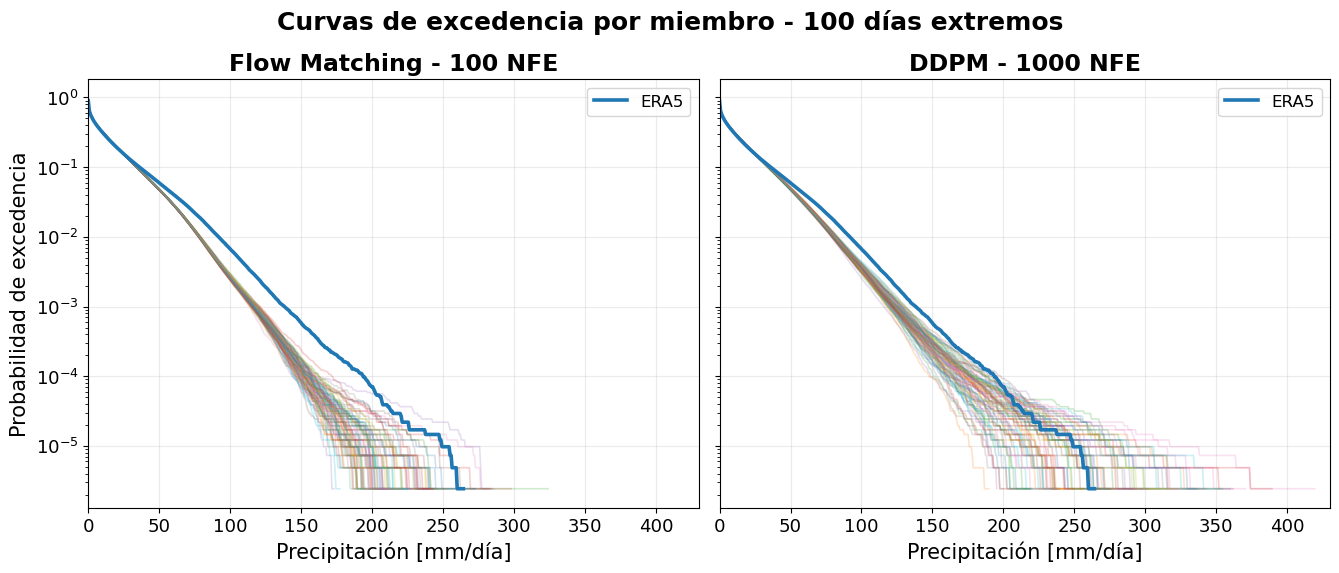

In [ ]:
# Parametros

FIGSIZE = (13.5, 5.8)

SUPTITLE_SIZE = 18
TITLE_SIZE = 17
LABEL_SIZE = 15
TICK_SIZE = 13
LEGEND_SIZE = 12

OBS_LINEWIDTH = 2.6
MEMBER_LINEWIDTH = 1.2
MEMBER_ALPHA = 0.22

XMIN = 0
XMAX = 430   # mismo rango para ambos paneles


fig, axes = plt.subplots(
    1,
    2,
    figsize=FIGSIZE,
    sharey=True,
)


ax = axes[0]

for member in range(80):

    y = exc_fm_members[member].copy()
    y[y == 0] = np.nan

    ax.plot(
        thresholds,
        y,
        alpha=MEMBER_ALPHA,
        linewidth=MEMBER_LINEWIDTH,
    )

obs_plot = exc_obs.copy()
obs_plot[obs_plot == 0] = np.nan

ax.plot(
    thresholds,
    obs_plot,
    linewidth=OBS_LINEWIDTH,
    label="ERA5",
)

ax.set_yscale("log")
ax.set_xlim(XMIN, XMAX)

ax.set_title(
    "Flow Matching - 100 NFE",
    fontsize=TITLE_SIZE,
    fontweight="bold",
)

ax.set_xlabel(
    "Precipitación [mm/día]",
    fontsize=LABEL_SIZE,
)

ax.set_ylabel(
    "Probabilidad de excedencia",
    fontsize=LABEL_SIZE,
)

ax.grid(alpha=0.25)
ax.legend(fontsize=LEGEND_SIZE)
ax.tick_params(labelsize=TICK_SIZE)


# DDPM
ax = axes[1]

for member in range(80):

    y = exc_ddpm_members[member].copy()
    y[y == 0] = np.nan

    ax.plot(
        thresholds,
        y,
        alpha=MEMBER_ALPHA,
        linewidth=MEMBER_LINEWIDTH,
    )

ax.plot(
    thresholds,
    obs_plot,
    linewidth=OBS_LINEWIDTH,
    label="ERA5",
)

ax.set_yscale("log")
ax.set_xlim(XMIN, XMAX)

ax.set_title(
    "DDPM - 1000 NFE",
    fontsize=TITLE_SIZE,
    fontweight="bold",
)

ax.set_xlabel(
    "Precipitación [mm/día]",
    fontsize=LABEL_SIZE,
)

ax.grid(alpha=0.25)
ax.legend(fontsize=LEGEND_SIZE)
ax.tick_params(labelsize=TICK_SIZE)


fig.suptitle(
    "Curvas de excedencia por miembro - 100 días extremos",
    fontsize=SUPTITLE_SIZE,
    fontweight="bold",
)

plt.tight_layout()
plt.show()